# Buscador de tasa de aprendizaje y one-cycle

El curso de fast.ai, *Practical Deep Learning for Coders*, enseña a entrenar redes con dos herramientas que su librería usa por defecto, ambas propuestas por Leslie Smith:

- **El buscador de tasa de aprendizaje** (`lr_find` en fastai). En lugar de adivinar la tasa, se hace un entrenamiento corto en el que la tasa sube de forma exponencial, y se mira dónde la pérdida baja más rápido.
- **La política one-cycle** (`fit_one_cycle`). En lugar de una tasa fija, la tasa sube hasta un máximo y después baja hasta casi cero, mientras el momento hace lo contrario.

Este notebook implementa las dos a mano, comprueba que la de one-cycle coincide con `torch.optim.lr_scheduler.OneCycleLR`, y compara el entrenamiento con tasa fija y con one-cycle.

**Contenido**

1. Preparación
2. El problema
3. Cuánto importa la tasa
4. El buscador de tasa
5. La política one-cycle
6. Tasa fija contra one-cycle
7. Por qué funciona
8. Resumen y ejercicios

## 1. Preparación

In [1]:
import math

import torch
from torch import nn
import matplotlib.pyplot as plt

print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 2. El problema

Una espiral de cinco brazos, más difícil que la de tres de `03_espiral_y_fronteras_de_decision`: 1000 puntos de entrenamiento y 1000 de prueba. La red tiene dos capas ocultas de 64 neuronas, y se entrena como se entrena en la práctica: con mini-batches de 32 ejemplos (`02-descenso-de-gradiente/02_sgd_y_minibatches`) y SGD con momento.

Todas las funciones fijan su semilla, así que cada entrenamiento parte de los mismos pesos y ve los lotes en el mismo orden. Lo único que cambia entre un experimento y otro es la tasa de aprendizaje.

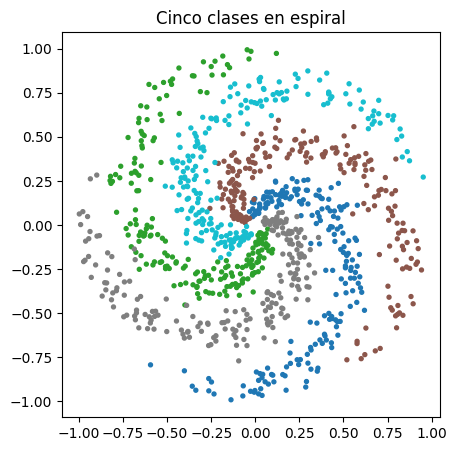

In [2]:
def espiral(puntos_por_clase=200, clases=5, ruido=0.25, semilla=0):
    generador = torch.Generator().manual_seed(semilla)
    X, y = [], []
    for clase in range(clases):
        radio = torch.linspace(0.05, 1, puntos_por_clase)
        inicio = clase * 4 * math.pi / clases
        angulo = torch.linspace(inicio, inicio + 3.5, puntos_por_clase)
        angulo = angulo + torch.randn(puntos_por_clase, generator=generador) * ruido
        X.append(torch.stack([radio * torch.sin(angulo), radio * torch.cos(angulo)], dim=1))
        y.append(torch.full((puntos_por_clase,), clase))
    return torch.cat(X), torch.cat(y)


X, y = espiral(semilla=0)
X_prueba, y_prueba = espiral(semilla=1)

TAMANO_LOTE = 32
PASOS_POR_EPOCA = math.ceil(len(X) / TAMANO_LOTE)


def nueva_red():
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 5))


def lotes(semilla):
    # Recorre los datos en orden aleatorio, época tras época, sin terminar nunca
    generador = torch.Generator().manual_seed(semilla)
    while True:
        orden = torch.randperm(len(X), generator=generador)
        for i in range(0, len(X), TAMANO_LOTE):
            indices = orden[i:i + TAMANO_LOTE]
            yield X[indices], y[indices]


def exactitud(red):
    with torch.no_grad():
        return (red(X_prueba).argmax(dim=1) == y_prueba).float().mean().item()


criterio = nn.CrossEntropyLoss()

plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="tab10", s=8)
plt.title("Cinco clases en espiral")
plt.gca().set_aspect("equal")
plt.show()

## 3. Cuánto importa la tasa

Antes de las herramientas, el problema que resuelven. Entrenamos 30 épocas con tasa fija, para varias tasas:

In [3]:
def entrenar_tasa_fija(lr, epocas=30):
    red = nueva_red()
    optimizador = torch.optim.SGD(red.parameters(), lr=lr, momentum=0.9)
    datos = lotes(semilla=1)
    perdidas = []
    for _ in range(epocas * PASOS_POR_EPOCA):
        xb, yb = next(datos)
        perdida = criterio(red(xb), yb)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
        perdidas.append(perdida.item())
    return red, perdidas


tasas = [0.003, 0.01, 0.03, 0.1, 0.3]
resultados_fija = {}
print("   tasa   pérdida final   exactitud de prueba")
for lr in tasas:
    red, perdidas = entrenar_tasa_fija(lr)
    final = sum(perdidas[-PASOS_POR_EPOCA:]) / PASOS_POR_EPOCA     # promedio de la última época
    resultados_fija[lr] = (final, exactitud(red), perdidas)
    print(f"{lr:7g} {final:15.3f} {resultados_fija[lr][1]:20.1%}")

   tasa   pérdida final   exactitud de prueba


  0.003           1.104                40.3%


   0.01           0.450                88.8%


   0.03           0.151                96.1%


    0.1           0.203                93.5%


    0.3           1.641                20.0%


Con tasas entre 0.003 y 0.3 la exactitud va de 40% a 96% y vuelve a caer a 20%, que es adivinar entre cinco clases. Con 0.003 la red casi no avanzó en 30 épocas. Con 0.3 diverge: su pérdida final, 1.64, está por encima de la de adivinar al azar ($\ln 5 \approx 1.61$). La mejor tasa de la lista es 0.03, y el rango que funciona razonablemente bien abarca apenas un factor de 10.

Encontrarlo así cuesta un entrenamiento completo por cada tasa probada. El buscador lo hace con uno solo, y corto.

## 4. El buscador de tasa

La idea de Smith: hacer **un solo** entrenamiento corto en el que la tasa empieza muy chica y se multiplica por un factor fijo en cada paso, hasta llegar a una tasa absurda. Al principio la pérdida casi no cambia (la tasa es muy chica para mover algo), después empieza a bajar, y al final explota (la tasa es demasiado grande). La curva de pérdida contra tasa, en escala logarítmica, muestra el rango útil.

Como la pérdida de cada mini-batch es ruidosa, se suaviza con un promedio móvil exponencial. Igual que en Adam (`04-matematica-de-pytorch/04_optimizadores`, sección 9), el promedio parte en 0 y está sesgado hacia abajo en los primeros pasos, así que se divide por $1 - \beta^t$. El buscador se detiene si la pérdida suavizada supera 4 veces la mínima vista.

pasos del buscador: 200
pérdida mínima en lr = 0.622
tasa sugerida (un orden de magnitud menos): 0.062


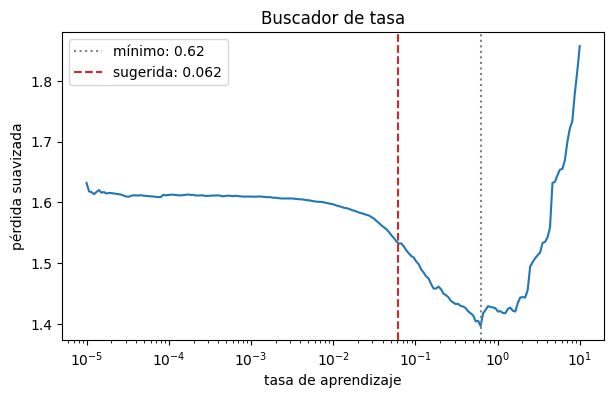

In [4]:
def buscar_tasa(lr_inicial=1e-5, lr_final=10.0, pasos=200, beta=0.98):
    red = nueva_red()
    optimizador = torch.optim.SGD(red.parameters(), lr=lr_inicial, momentum=0.9)
    datos = lotes(semilla=0)
    factor = (lr_final / lr_inicial) ** (1 / (pasos - 1))

    tasas, perdidas = [], []
    promedio, mejor = 0.0, float("inf")
    for paso in range(pasos):
        lr = lr_inicial * factor ** paso
        for grupo in optimizador.param_groups:
            grupo["lr"] = lr

        xb, yb = next(datos)
        perdida = criterio(red(xb), yb)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()

        promedio = beta * promedio + (1 - beta) * perdida.item()
        suavizada = promedio / (1 - beta ** (paso + 1))
        tasas.append(lr)
        perdidas.append(suavizada)
        mejor = min(mejor, suavizada)
        if suavizada > 4 * mejor:
            break
    return tasas, perdidas


tasas_buscador, perdidas_buscador = buscar_tasa()
i_minimo = min(range(len(perdidas_buscador)), key=lambda i: perdidas_buscador[i])
lr_minimo = tasas_buscador[i_minimo]
lr_sugerida = lr_minimo / 10
print(f"pasos del buscador: {len(tasas_buscador)}")
print(f"pérdida mínima en lr = {lr_minimo:.3f}")
print(f"tasa sugerida (un orden de magnitud menos): {lr_sugerida:.3f}")

plt.figure(figsize=(7, 4))
plt.semilogx(tasas_buscador, perdidas_buscador)
plt.axvline(lr_minimo, color="gray", linestyle=":", label=f"mínimo: {lr_minimo:.2f}")
plt.axvline(lr_sugerida, color="tab:red", linestyle="--", label=f"sugerida: {lr_sugerida:.3f}")
plt.xlabel("tasa de aprendizaje")
plt.ylabel("pérdida suavizada")
plt.title("Buscador de tasa")
plt.legend()
plt.show()

La curva tiene las tres zonas. Hasta $10^{-3}$ la pérdida se queda en 1.61, la de adivinar entre cinco clases: con una tasa tan chica, en pocos pasos la red no aprende nada. Desde ahí baja, cada vez más rápido, hasta un mínimo en 0.62, y después sube. No alcanzó a cuadruplicarse, así que el buscador recorrió los 200 pasos.

¿Por qué no usar la tasa del mínimo? Porque en el buscador cada tasa se usa solo un par de pasos. En 0.62 la pérdida todavía bajaba mientras la tasa subía, pero un entrenamiento completo con esa tasa diverge: la sección 3 mostró que 0.3 ya diverge. La regla de fast.ai es elegir en la zona de bajada pronunciada, alrededor de un orden de magnitud antes del mínimo. Aquí da 0.062, entre las dos mejores tasas fijas de la sección 3 (0.03 y 0.1), con un entrenamiento de 200 pasos en vez de cinco de 960.

## 5. La política one-cycle

Smith propuso no usar una tasa fija, sino un **ciclo**:

1. **Subida** (el primer 30% de los pasos): la tasa sube desde $\eta_{\max} / 25$ hasta $\eta_{\max}$.
2. **Bajada** (el 70% restante): baja desde $\eta_{\max}$ hasta $\eta_{\max} / (25 \cdot 10^4)$, prácticamente 0.

Las dos fases usan medio coseno para pasar suavemente de un valor a otro:

$$\text{coseno}(a, b, p) = b + \frac{a - b}{2}\big(1 + \cos(\pi p)\big)$$

que vale $a$ cuando el avance $p$ es 0 y $b$ cuando es 1. El **momento** hace el camino inverso: baja de 0.95 a 0.85 mientras la tasa sube, y vuelve a 0.95 mientras baja.

Lo implementamos a mano con los mismos valores por defecto de `OneCycleLR` (en PyTorch, el fin de la subida es el paso $0.3 \cdot T - 1$, contando desde 0):

In [5]:
def coseno(inicio, fin, avance):
    return fin + (inicio - fin) / 2 * (1 + math.cos(math.pi * avance))


def one_cycle(paso, total, lr_max, pct_subida=0.3, div=25.0, div_final=1e4, momento_min=0.85, momento_max=0.95):
    lr_inicial = lr_max / div
    lr_final = lr_inicial / div_final
    fin_subida = pct_subida * total - 1
    if paso <= fin_subida:
        avance = paso / fin_subida
        return coseno(lr_inicial, lr_max, avance), coseno(momento_max, momento_min, avance)
    avance = (paso - fin_subida) / (total - 1 - fin_subida)
    return coseno(lr_max, lr_final, avance), coseno(momento_min, momento_max, avance)

Y lo comparamos con el de PyTorch, leyendo la tasa y el momento que `OneCycleLR` le pone al optimizador antes de cada paso:

pasos: 960
diferencia máxima en la tasa:   0.0e+00
diferencia máxima en el momento: 0.0e+00
¿coinciden? True


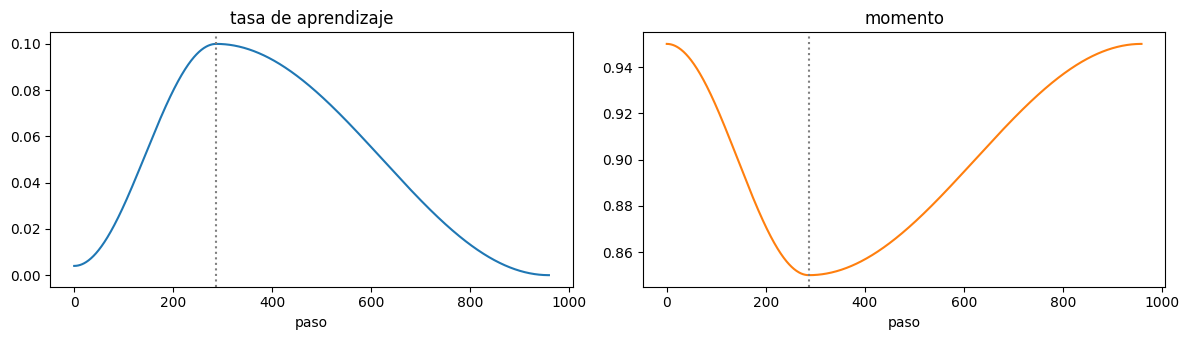

In [6]:
total = 30 * PASOS_POR_EPOCA
lr_max = 0.1

parametro = torch.zeros(1, requires_grad=True)
optimizador = torch.optim.SGD([parametro], lr=lr_max, momentum=0.9)
programador = torch.optim.lr_scheduler.OneCycleLR(optimizador, max_lr=lr_max, total_steps=total)

de_pytorch, a_mano = [], []
for paso in range(total):
    grupo = optimizador.param_groups[0]
    de_pytorch.append((grupo["lr"], grupo["momentum"]))
    a_mano.append(one_cycle(paso, total, lr_max))
    optimizador.step()
    programador.step()

de_pytorch = torch.tensor(de_pytorch, dtype=torch.float64)
a_mano = torch.tensor(a_mano, dtype=torch.float64)
print(f"pasos: {total}")
print(f"diferencia máxima en la tasa:   {(de_pytorch[:, 0] - a_mano[:, 0]).abs().max():.1e}")
print(f"diferencia máxima en el momento: {(de_pytorch[:, 1] - a_mano[:, 1]).abs().max():.1e}")
print("¿coinciden?", torch.allclose(de_pytorch, a_mano))

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))
ejes[0].plot(a_mano[:, 0])
ejes[0].set_title("tasa de aprendizaje")
ejes[1].plot(a_mano[:, 1], color="tab:orange")
ejes[1].set_title("momento")
for eje in ejes:
    eje.set_xlabel("paso")
    eje.axvline(0.3 * total - 1, color="gray", linestyle=":")
plt.tight_layout()
plt.show()

Coinciden en todos los pasos. Para usarlo en un entrenamiento basta crear el `OneCycleLR` y llamar a `programador.step()` después de cada `optimizador.step()`. Ojo: el programador se avanza **por paso** (por mini-batch), no por época, y `total_steps` tiene que ser el número total de pasos.

## 6. Tasa fija contra one-cycle

Repetimos el experimento de la sección 3 con one-cycle, usando cada tasa como $\eta_{\max}$. Agregamos la tasa que sugirió el buscador y una tasa de 1, que con tasa fija no tiene ninguna posibilidad:

In [7]:
def entrenar_one_cycle(lr_max, epocas=30):
    red = nueva_red()
    optimizador = torch.optim.SGD(red.parameters(), lr=lr_max, momentum=0.9)
    total = epocas * PASOS_POR_EPOCA
    programador = torch.optim.lr_scheduler.OneCycleLR(optimizador, max_lr=lr_max, total_steps=total)
    datos = lotes(semilla=1)
    perdidas = []
    for _ in range(total):
        xb, yb = next(datos)
        perdida = criterio(red(xb), yb)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
        programador.step()
        perdidas.append(perdida.item())
    return red, perdidas


resultados_ciclo = {}
print("   tasa   tasa fija: pérdida  exactitud   one-cycle: pérdida  exactitud")
for lr in sorted(tasas + [round(lr_sugerida, 3), 1.0]):
    if lr not in resultados_fija:
        red, perdidas = entrenar_tasa_fija(lr)
        resultados_fija[lr] = (sum(perdidas[-PASOS_POR_EPOCA:]) / PASOS_POR_EPOCA, exactitud(red), perdidas)
    red, perdidas = entrenar_one_cycle(lr)
    resultados_ciclo[lr] = (sum(perdidas[-PASOS_POR_EPOCA:]) / PASOS_POR_EPOCA, exactitud(red), perdidas)
    f, c = resultados_fija[lr], resultados_ciclo[lr]
    print(f"{lr:7g} {f[0]:17.3f} {f[1]:10.1%} {c[0]:19.3f} {c[1]:10.1%}")

   tasa   tasa fija: pérdida  exactitud   one-cycle: pérdida  exactitud


  0.003             1.104      40.3%               1.185      36.9%


   0.01             0.450      88.8%               1.004      46.9%


   0.03             0.151      96.1%               0.260      92.7%


  0.062             0.178      94.4%               0.095      97.3%


    0.1             0.203      93.5%               0.062      97.3%


    0.3             1.641      20.0%               0.058      97.0%


      1             1.693      20.0%               1.610      20.0%


Tres cosas se ven en la tabla:

- **One-cycle tolera tasas mucho más altas.** Con tasa fija, 0.3 diverge. Con one-cycle, esa misma tasa como máximo llega a 97%.
- **Con una tasa máxima buena, one-cycle gana.** Sus mejores resultados (97.3% con 0.062 y con 0.1) superan a la mejor tasa fija (96.1% con 0.03), con una pérdida final bastante menor. La tasa que sugirió el buscador está entre las mejores.
- **Con un máximo chico, one-cycle pierde.** Con 0.01 o 0.03 como máximo, la tasa promedio del ciclo es alrededor de la mitad del máximo, así que la red avanza menos que con esa misma tasa fija. El $\eta_{\max}$ de one-cycle tiene que ser alto, y para eso está el buscador.

Con 1, ni siquiera one-cycle se salva: la tasa máxima es demasiado grande para cualquier calendario.

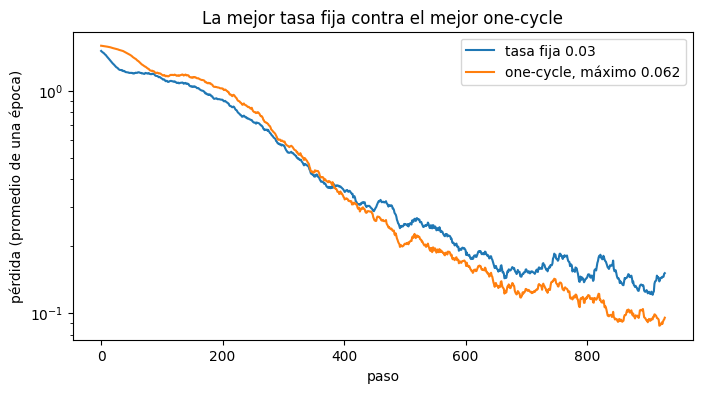

In [8]:
mejor_fija = max(resultados_fija, key=lambda lr: resultados_fija[lr][1])
mejor_ciclo = max(resultados_ciclo, key=lambda lr: resultados_ciclo[lr][1])


def suavizar(valores, ventana=PASOS_POR_EPOCA):
    valores = torch.tensor(valores)
    return valores.unfold(0, ventana, 1).mean(dim=1)


plt.figure(figsize=(8, 4))
plt.plot(suavizar(resultados_fija[mejor_fija][2]), label=f"tasa fija {mejor_fija:g}")
plt.plot(suavizar(resultados_ciclo[mejor_ciclo][2]), label=f"one-cycle, máximo {mejor_ciclo:g}")
plt.yscale("log")
plt.xlabel("paso")
plt.ylabel("pérdida (promedio de una época)")
plt.title("La mejor tasa fija contra el mejor one-cycle")
plt.legend()
plt.show()

Al principio one-cycle va más lento: su tasa parte 25 veces por debajo del máximo. Hacia el paso 350 alcanza a la tasa fija y desde ahí la supera. En el último tercio la diferencia se agranda: la tasa fija se estanca y oscila alrededor de 0.15, porque el ruido de los mini-batches no deja que se asiente, mientras one-cycle, con la tasa cayendo hacia 0, sigue bajando.

## 7. Por qué funciona

Smith y fast.ai lo justifican con argumentos empíricos más que con un teorema, pero cada fase tiene una razón:

- **La subida** (*warm-up*). Al principio los pesos son aleatorios y los gradientes pueden ser grandes y poco informativos. Empezar con una tasa 25 veces menor evita que los primeros pasos manden la red a una zona de la que no se recupera, que es lo que le pasó a la tasa fija de 0.3.
- **La tasa alta en el medio.** Los pasos grandes recorren la superficie de pérdida rápido y no dejan que la red se asiente en un mínimo estrecho y anguloso. El ruido de los mini-batches, amplificado por la tasa alta, funciona como una forma de regularización.
- **La bajada hasta casi 0.** Con tasa fija, el ruido de los mini-batches mantiene a los parámetros rebotando alrededor del mínimo, a una distancia proporcional a la tasa (se vio en `02-descenso-de-gradiente/02_sgd_y_minibatches`). Bajar la tasa al final elimina ese rebote y deja a la red en el fondo.
- **El momento al revés.** El momento acumula pasos anteriores, así que el paso efectivo crece con él. Bajarlo cuando la tasa es máxima evita que los dos efectos se sumen y desestabilicen el entrenamiento.

El buscador de tasa complementa al ciclo: da el $\eta_{\max}$ sin tener que entrenar muchas veces, que es lo que hicimos en la sección 6 para poder comparar.

## 8. Resumen

- La tasa de aprendizaje fija tiene un rango útil estrecho: un poco por debajo, el entrenamiento es lento; un poco por encima, diverge.
- El **buscador de tasa** hace un solo entrenamiento corto subiendo la tasa exponencialmente y grafica la pérdida suavizada. La tasa a usar está en la zona de bajada, alrededor de un orden de magnitud por debajo del mínimo de la curva.
- La política **one-cycle** sube la tasa de $\eta_{\max}/25$ a $\eta_{\max}$ en el primer 30% de los pasos y la baja hasta casi 0 en el resto, con el momento en sentido inverso. La implementación a mano coincide con `torch.optim.lr_scheduler.OneCycleLR`.
- `OneCycleLR` se avanza una vez por mini-batch, con `total_steps` igual al total de pasos del entrenamiento.
- Con one-cycle, el entrenamiento tolera tasas máximas más altas que con tasa fija y, en este problema, llega a una pérdida y una exactitud mejores en el mismo número de épocas.

## Ejercicios

1. Repite el buscador con `beta=0.9` y con `beta=0.995`. ¿Cómo cambia la curva? ¿Cambia mucho la tasa sugerida?
2. Corre el buscador con otras dos semillas de `lotes`. ¿Qué tan estable es la tasa sugerida?
3. Entrena con one-cycle cambiando `pct_start` a 0.1 y a 0.5 (es un argumento de `OneCycleLR`). ¿Qué fase parece importar más?
4. Reemplaza `torch.optim.SGD` por `torch.optim.Adam` en `entrenar_one_cycle`. `OneCycleLR` cicla entonces el primer coeficiente de `betas` en lugar del momento. Corre el buscador con Adam: ¿la tasa sugerida se parece a la de SGD?
5. Con tasa fija, agrega un *warm-up* lineal de 2 épocas (de 0 a la tasa elegida) antes de mantenerla constante. ¿Alcanza para que la tasa 0.3 deje de diverger?